<a href="https://colab.research.google.com/github/Tonikaneprv/PDA/blob/lab3/%D0%9B%D0%A04_%D0%92%D0%B5%D0%B4%D0%B5%D1%80%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D0%B0_PokeAPI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Часть 1. Сбор данных (опция 3)




In [1]:
%pip install -q requests pandas matplotlib seaborn scipy sqlalchemy

In [2]:
import json
import os
import time
from concurrent.futures import ThreadPoolExecutor
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

### Сбор данных (Extract)


| Эндпоинт | Сколько запросов | Что берём |
|---|---|---|
| `/version-group/{id}` | ~30 | порядковый номер игры (`order`), чтобы выбрать самую новую игру |
| `/pokemon/{id}` | 1025 | тип(ы), характеристики, **список приёмов** со способом и уровнем изучения |
| `/pokemon-species/{id}` | 1025 | поколение, легендарность / мифичность |
| `/move/{id}` | ~800 | тип приёма, класс урона, сила, точность, PP, приоритет, поколение |

Первый запуск занимает несколько минут (около 2900 запросов).

In [3]:
BASE_URL = "https://pokeapi.co/api/v2"
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

session = requests.Session()
session.headers.update({"User-Agent": "popa"})


def id_from_url(url: str) -> int:
    return int(url.rstrip("/").split("/")[-1])


def get_json(endpoint: str, key, retries: int = 3) -> Optional[dict]:
    path = os.path.join(CACHE_DIR, f"{endpoint}_{key}.json")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    for attempt in range(1, retries + 1):
        try:
            resp = session.get(f"{BASE_URL}/{endpoint}/{key}/", timeout=20)
            if resp.status_code == 404:
                return None
            resp.raise_for_status()
            data = resp.json()
            with open(path, "w", encoding="utf-8") as f:
                json.dump(data, f)
            return data
        except requests.RequestException:
            if attempt == retries:
                raise
            time.sleep(attempt)


def fetch_all(endpoint: str, keys, max_workers: int = 8) -> list:
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        return [r for r in pool.map(lambda k: get_json(endpoint, k), keys) if r is not None]

In [4]:
N_POKEMON = 1025

t0 = time.perf_counter()

vg_list = session.get(f"{BASE_URL}/version-group/?limit=100", timeout=20).json()["results"]
version_groups = fetch_all("version-group", [id_from_url(v["url"]) for v in vg_list])
vg_order = {v["name"]: v["order"] for v in version_groups}
print(f"Игр (version groups): {len(vg_order)}")

pokemon_raw = fetch_all("pokemon", range(1, N_POKEMON + 1))
print(f"Покемонов: {len(pokemon_raw)}")

species_raw = fetch_all("pokemon-species", sorted({id_from_url(p["species"]["url"]) for p in pokemon_raw}))
print(f"Видов: {len(species_raw)}")

move_ids = sorted({id_from_url(m["move"]["url"]) for p in pokemon_raw for m in p["moves"]})
moves_raw = fetch_all("move", move_ids)
print(f"Приёмов: {len(moves_raw)}")

print(f"Сбор занял {time.perf_counter() - t0:.1f} с")

Игр (version groups): 32
Покемонов: 1025
Видов: 1025
Приёмов: 798
Сбор занял 66.9 с


In [5]:
STAT_COLUMNS = {"hp": "hp", "attack": "attack", "defense": "defense",
                "special-attack": "sp_attack", "special-defense": "sp_defense", "speed": "speed"}
METHOD_PRIORITY = {"level-up": 0, "machine": 1, "egg": 2, "tutor": 3}

species_by_id = {s["id"]: s for s in species_raw}

pokemon_rows, link_rows = [], []
for p in pokemon_raw:
    s = species_by_id[id_from_url(p["species"]["url"])]
    st = {STAT_COLUMNS[x["stat"]["name"]]: x["base_stat"] for x in p["stats"]}
    types = {t["slot"]: t["type"]["name"] for t in p["types"]}
    pokemon_rows.append({
        "id": p["id"], "name": p["name"],
        "generation": id_from_url(s["generation"]["url"]),
        "is_legendary": s["is_legendary"], "is_mythical": s["is_mythical"],
        "primary_type": types.get(1), "secondary_type": types.get(2),
        **st, "total_stats": sum(st.values()),
    })
    for m in p["moves"]:
        details = [d for d in m["version_group_details"]
                   if d["move_learn_method"]["name"] in METHOD_PRIORITY]
        if not details:
            continue
        latest = max(vg_order[d["version_group"]["name"]] for d in details)
        best = min(
            (d for d in details if vg_order[d["version_group"]["name"]] == latest),
            key=lambda d: (METHOD_PRIORITY[d["move_learn_method"]["name"]], d["level_learned_at"]),
        )
        link_rows.append({
            "pokemon_id": p["id"],
            "move_id": id_from_url(m["move"]["url"]),
            "learn_method": best["move_learn_method"]["name"],
            "level_learned": best["level_learned_at"],
            "version_group": best["version_group"]["name"],
        })

move_rows = [{
    "id": m["id"], "name": m["name"],
    "type": m["type"]["name"],
    "damage_class": m["damage_class"]["name"] if m["damage_class"] else None,
    "power": m["power"], "accuracy": m["accuracy"], "pp": m["pp"], "priority": m["priority"],
    "generation": id_from_url(m["generation"]["url"]),
} for m in moves_raw]

tbl_pokemon = pd.DataFrame(pokemon_rows)
tbl_moves = pd.DataFrame(move_rows)
tbl_links = pd.DataFrame(link_rows)
print(tbl_pokemon.shape, tbl_moves.shape, tbl_links.shape)

(1025, 14) (798, 9) (79604, 5)


In [6]:
engine = create_engine("sqlite:///pokemon_eda.db")
tbl_pokemon.to_sql("pokemon", engine, if_exists="replace", index=False)
tbl_moves.to_sql("moves", engine, if_exists="replace", index=False)
tbl_links.to_sql("pokemon_moves", engine, if_exists="replace", index=False)

DATASET_SQL = """
SELECT
    p.name                       AS pokemon,
    p.generation                 AS pokemon_generation,
    CASE WHEN p.is_legendary THEN 'legendary'
         WHEN p.is_mythical  THEN 'mythical'
         ELSE 'regular' END      AS pokemon_category,
    p.primary_type, p.secondary_type,
    p.attack, p.sp_attack, p.total_stats,
    m.name                       AS move,
    m.type                       AS move_type,
    m.damage_class, m.power, m.accuracy, m.pp, m.priority,
    m.generation                 AS move_generation,
    pm.learn_method, pm.level_learned
FROM pokemon_moves AS pm
JOIN pokemon AS p ON p.id = pm.pokemon_id
JOIN moves   AS m ON m.id = pm.move_id
ORDER BY p.id, m.id
"""
raw = pd.read_sql(DATASET_SQL, engine)

raw["stab"] = (raw["move_type"] == raw["primary_type"]) | (raw["move_type"] == raw["secondary_type"])

raw.to_csv("pokemon_moves_dataset.csv", index=False)
print(raw.shape)

(79604, 19)


### 1.5. Очистка и первичный осмотр

In [7]:
df = raw.copy()

bad_power = df["power"] <= 1
bad_acc = df["accuracy"] == 0
print("Приёмов с силой 0/1:", df.loc[bad_power, "move"].nunique(),
      "| с точностью 0:", df.loc[bad_acc, "move"].nunique())
df.loc[bad_power, "power"] = np.nan
df.loc[bad_acc, "accuracy"] = np.nan


df["learn_method"] = pd.Categorical(df["learn_method"], ["level-up", "machine", "egg", "tutor"])
df["damage_class"] = pd.Categorical(df["damage_class"], ["physical", "special", "status"])
df["pokemon_category"] = pd.Categorical(df["pokemon_category"], ["regular", "legendary", "mythical"])


moves_u = df.drop_duplicates("move").reset_index(drop=True)
poke_u = (df.groupby("pokemon", observed=True)
            .agg(pokemon_generation=("pokemon_generation", "first"),
                 pokemon_category=("pokemon_category", "first"),
                 primary_type=("primary_type", "first"),
                 secondary_type=("secondary_type", "first"),
                 attack=("attack", "first"), sp_attack=("sp_attack", "first"),
                 total_stats=("total_stats", "first"),
                 movepool=("move", "count"))
            .reset_index())

print(f"Объектов (пар «покемон — приём»): {len(df):,}")
print(f"Уникальных покемонов: {df['pokemon'].nunique()} | уникальных приёмов: {df['move'].nunique()}")
print(f"Признаков: {df.shape[1]}")
df.head()

Приёмов с силой 0/1: 17 | с точностью 0: 3
Объектов (пар «покемон — приём»): 79,604
Уникальных покемонов: 1025 | уникальных приёмов: 797
Признаков: 19


,pokemon,pokemon_generation,pokemon_category,primary_type,secondary_type,attack,sp_attack,total_stats,move,move_type,damage_class,power,accuracy,pp,priority,move_generation,learn_method,level_learned,stab
0,bulbasaur,1,regular,grass,poison,49,65,318,razor-wind,normal,special,80.0,100.0,10,0,1,egg,0,False
1,bulbasaur,1,regular,grass,poison,49,65,318,swords-dance,normal,status,NaN,NaN,20,0,1,machine,0,False
2,bulbasaur,1,regular,grass,poison,49,65,318,cut,normal,physical,50.0,95.0,30,0,1,machine,0,False
3,bulbasaur,1,regular,grass,poison,49,65,318,bind,normal,physical,15.0,85.0,20,0,1,tutor,0,False
4,bulbasaur,1,regular,grass,poison,49,65,318,vine-whip,grass,physical,45.0,100.0,25,0,1,level-up,3,True


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79604 entries, 0 to 79603
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   pokemon             79604 non-null  object  
 1   pokemon_generation  79604 non-null  int64   
 2   pokemon_category    79604 non-null  category
 3   primary_type        79604 non-null  object  
 4   secondary_type      41616 non-null  object  
 5   attack              79604 non-null  int64   
 6   sp_attack           79604 non-null  int64   
 7   total_stats         79604 non-null  int64   
 8   move                79604 non-null  object  
 9   move_type           79604 non-null  object  
 10  damage_class        79604 non-null  category
 11  power               45398 non-null  float64 
 12  accuracy            57063 non-null  float64 
 13  pp                  79604 non-null  int64   
 14  priority            79604 non-null  int64   
 15  move_generation     79604 non-null  

In [9]:

df.isna().mean().mul(100).round(1).rename("пропусков, %").to_frame().query("`пропусков, %` > 0")

,"пропусков, %"
secondary_type,47.7
power,43.0
accuracy,28.3


In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pokemon_generation,79604.0,4.27,2.51,1.0,2.0,4.0,6.0,9.0
attack,79604.0,79.78,29.47,5.0,58.0,79.0,100.0,181.0
sp_attack,79604.0,72.32,29.31,10.0,50.0,65.0,95.0,173.0
total_stats,79604.0,439.05,109.18,175.0,335.0,460.0,515.0,720.0
power,45398.0,74.41,30.02,10.0,60.0,70.0,90.0,250.0
accuracy,57063.0,96.24,8.23,30.0,95.0,100.0,100.0,100.0
pp,79604.0,15.16,7.30,1.0,10.0,15.0,20.0,40.0
priority,79604.0,0.10,1.08,-7.0,0.0,0.0,0.0,5.0
move_generation,79604.0,2.91,1.97,1.0,1.0,2.0,4.0,9.0
level_learned,79604.0,5.21,13.39,0.0,0.0,0.0,0.0,100.0


### 1.6. Описание признаков

| № | Признак | Описание | Тип данных | Шкала |
|---|---|---|---|---|
| 1 | `pokemon` | имя покемона | строка | номинальная (идентификатор) |
| 2 | `pokemon_generation` | поколение, в котором появился покемон (1–9) | целое | порядковая |
| 3 | `pokemon_category` | обычный / легендарный / мифический | категория | номинальная |
| 4 | `primary_type` | основной тип покемона (18 значений) | категория | номинальная |
| 5 | `secondary_type` | дополнительный тип; пропуск = у покемона один тип | категория | номинальная |
| 6 | `attack` | базовая физическая атака | целое | отношений |
| 7 | `sp_attack` | базовая специальная атака | целое | отношений |
| 8 | `total_stats` | сумма 6 базовых характеристик | целое | отношений |
| 9 | `move` | название приёма | строка | номинальная (идентификатор) |
| 10 | `move_type` | тип приёма (18 значений) | категория | номинальная |
| 11 | `damage_class` | physical / special / status (урон от атаки, урон от спец. атаки, без урона) | категория | номинальная |
| 12 | `power` | сила приёма; пропуск = приём не наносит прямого урона или сила переменная | вещественное | отношений |
| 13 | `accuracy` | точность, %; пропуск = приём не может промахнуться | вещественное | отношений |
| 14 | `pp` | сколько раз можно использовать приём | целое | отношений |
| 15 | `priority` | приоритет хода (от −7 до +5, 0 — обычный) | целое | интервальная (нуля как «отсутствия» нет, сравниваются разности) |
| 16 | `move_generation` | поколение, в котором появился приём | целое | порядковая |
| 17 | `learn_method` | способ изучения: level-up / machine / egg / tutor | категория | номинальная |
| 18 | `level_learned` | уровень изучения (только для level-up; иначе 0) | целое | отношений |
| 19 | `stab` | совпадает ли тип приёма с типом покемона (бонус урона ×1.5) | логический | номинальная (бинарная) |

**Для каких задач подходит датасет:** анализ того, как устроены наборы приёмов (movepool) покемонов; сравнение физических и специальных приёмов; классификация способа изучения или класса урона по признакам; рекомендация приёмов покемону (задача «пользователь — объект»).

**Для каких не подходит:** предсказание исхода боёв (нет данных о боях, погоде, предметах, реальной популярности приёмов у игроков); анализ «силы покемона» как самостоятельного объекта — характеристики покемона повторяются в каждой его строке, поэтому статистики по покемонам нужно считать на уникальных покемонах (`poke_u`), а по приёмам — на уникальных приёмах (`moves_u`), иначе покемоны с большим набором приёмов получат больший вес.

#  Разведочный анализ




## График 1. Способ изучения приёмов (`learn_method`)

**Гипотеза 1.** Большую часть приёмов покемоны получают не по уровню, а через TM (`machine`): TM универсальны и подходят многим покемонам сразу.

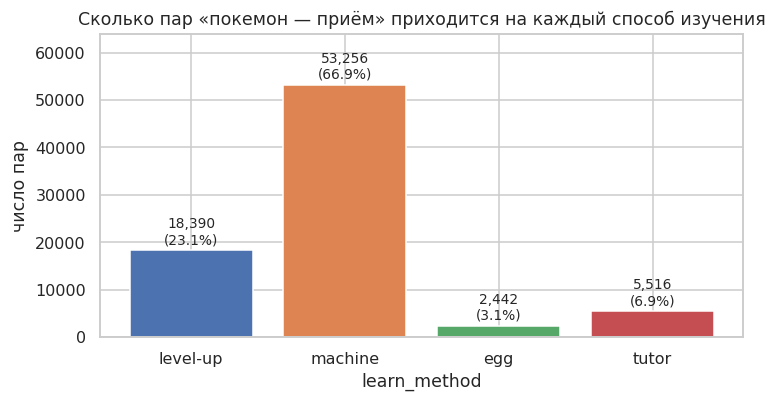

In [11]:
counts = df["learn_method"].value_counts().reindex(df["learn_method"].cat.categories)
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette("deep", 4))
ax.bar_label(bars, labels=[f"{v:,}\n({s:.1f}%)" for v, s in zip(counts, shares)], padding=2, fontsize=9)
ax.set_title("Сколько пар «покемон — приём» приходится на каждый способ изучения")
ax.set_xlabel("learn_method"); ax.set_ylabel("число пар")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()

**Вывод 1.** Гипотеза **подтверждается**. Через TM (`machine`) покемоны получают 66.9% всех приёмов (≈53 тыс. пар), по уровню только 23.1%, у учителя 6.9%, через разведение 3.1%. Статистический тест здесь не нужен: в датасете все 1025 покемонов, то есть вся генеральная совокупность, а не выборка, и доли посчитаны точно. Из графика также видно, что «естественный» набор (level-up + egg) составляет меньше трети: основное разнообразие приёмов дают универсальные TM.

## График 2. Уровень изучения (`level_learned`)

`level_learned` имеет смысл только для `level-up` (у остальных способов он всегда 0), поэтому строим распределение только по ним.

**Гипотеза 2.** Большинство приёмов по уровню покемон получает на ранних уровнях (до 30), а распределение скошено вправо: чем выше уровень, тем меньше новых приёмов.

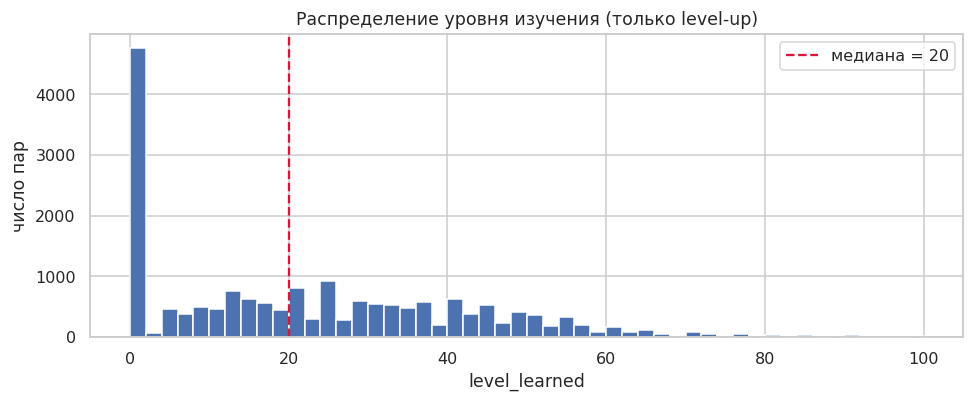

Доля приёмов на уровнях 0–1 (стартовые и при эволюции): 25.9%
Доля приёмов до 30 уровня включительно: 67.3%
Коэффициент асимметрии: 0.71


In [12]:
lv = df.loc[df["learn_method"] == "level-up", "level_learned"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(lv, bins=range(0, 102, 2), color="#4C72B0", edgecolor="white")
ax.axvline(lv.median(), color="crimson", ls="--", label=f"медиана = {lv.median():.0f}")
ax.set_title("Распределение уровня изучения (только level-up)")
ax.set_xlabel("level_learned"); ax.set_ylabel("число пар"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Доля приёмов на уровнях 0–1 (стартовые и при эволюции): {(lv <= 1).mean():.1%}")
print(f"Доля приёмов до 30 уровня включительно: {(lv <= 30).mean():.1%}")
print(f"Коэффициент асимметрии: {lv.skew():.2f}")

**Вывод 2.** Гипотеза **подтверждается**. Медиана уровня изучения 20, две трети (67.3%) приёмов по уровню покемон получает до 30 уровня включительно. Распределение скошено вправо (асимметрия 0.71): после 50 уровня новых приёмов мало. Отдельно выделяется пик в самом начале: 25.9% приёмов приходится на уровни 0–1. Это стартовые приёмы (уровень 1) и приёмы, которые даются при эволюции (в новых играх у них уровень 0). Сами «пиковые» значения — особенность того, как API кодирует эти случаи, а не реальное обучение на 0-м уровне.

## График 3. Класс урона (`damage_class`): среди приёмов и среди пар

**Гипотеза 3.** Физических приёмов в игре больше всего. При этом среди пар доля статусных (`status`) приёмов выше, чем среди уникальных приёмов: универсальные статусные приёмы вроде Protect или Rest могут выучить почти все покемоны.

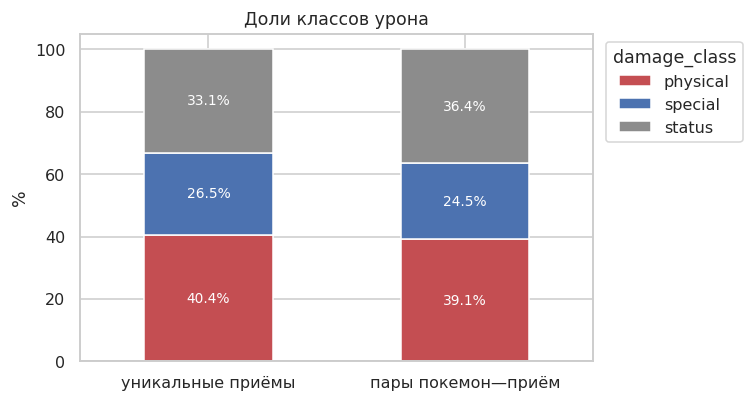

damage_class
physical    46.0
special     43.0
status      43.0
Name: медиана покемонов на приём, dtype: float64
Манн–Уитни (status > атакующие): p = 0.215


In [13]:
cmp = pd.DataFrame({
    "уникальные приёмы": moves_u["damage_class"].value_counts(normalize=True),
    "пары покемон—приём": df["damage_class"].value_counts(normalize=True),
}).reindex(["physical", "special", "status"]) * 100

ax = cmp.T.plot(kind="bar", stacked=True, figsize=(7, 3.8), rot=0,
                color=["#C44E52", "#4C72B0", "#8C8C8C"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Доли классов урона"); ax.set_ylabel("%")
ax.legend(title="damage_class", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

learners = df.groupby("move", observed=True).size().rename("learners")
mu = moves_u.set_index("move").join(learners)
res = stats.mannwhitneyu(mu.loc[mu["damage_class"] == "status", "learners"],
                         mu.loc[mu["damage_class"] != "status", "learners"], alternative="greater")
print(mu.groupby("damage_class", observed=True)["learners"].median().rename("медиана покемонов на приём"))
print(f"Манн–Уитни (status > атакующие): p = {res.pvalue:.3g}")

**Вывод 3.** Гипотеза **подтверждается частично**. Первая часть верна: среди уникальных приёмов больше всего физических (40.4%), статусных 33.1%, специальных 26.5%. Вторая часть верна только в целом: доля статусных среди пар выше (36.4% против 33.1%), но тест Манна–Уитни не показывает, что *типичный* статусный приём учит больше покемонов, чем атакующий (медиана 43 покемона у статусных против 46 у физических и 43 у специальных, p = 0.21 > 0.05). Значит, рост доли дают не все статусные приёмы, а несколько универсальных, которые есть почти у всех покемонов. Это видно на графике 16.

## График 4. Сила приёма (`power`) по классу урона

Считаем по уникальным приёмам, у которых сила задана (статусные отпадают сами).

**Гипотеза 4.** Специальные приёмы в среднем сильнее физических.

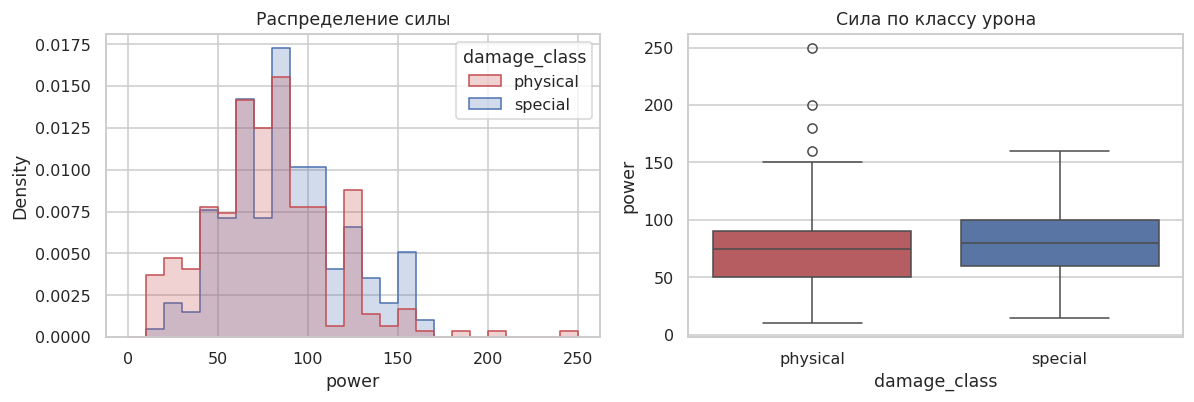

              count  mean   std   min   25%   50%    75%    max
damage_class                                                   
physical      296.0  74.2  34.0  10.0  50.0  75.0   90.0  250.0
special       197.0  84.1  31.9  15.0  60.0  80.0  100.0  160.0
Манн–Уитни (special > physical): p = 0.000354


In [14]:
dmg_moves = moves_u.dropna(subset=["power"]).query("damage_class != 'status'").copy()
dmg_moves["damage_class"] = dmg_moves["damage_class"].cat.remove_unused_categories()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=dmg_moves, x="power", hue="damage_class", bins=range(0, 260, 10),
             element="step", stat="density", common_norm=False,
             palette={"physical": "#C44E52", "special": "#4C72B0"}, ax=axes[0])
axes[0].set_title("Распределение силы")
sns.boxplot(data=dmg_moves, x="damage_class", y="power", hue="damage_class", legend=False,
            palette={"physical": "#C44E52", "special": "#4C72B0"}, ax=axes[1])
axes[1].set_title("Сила по классу урона")
plt.tight_layout(); plt.show()

print(dmg_moves.groupby("damage_class", observed=True)["power"].describe().round(1))
res = stats.mannwhitneyu(dmg_moves.query("damage_class == 'special'")["power"],
                         dmg_moves.query("damage_class == 'physical'")["power"], alternative="greater")
print(f"Манн–Уитни (special > physical): p = {res.pvalue:.3g}")

**Вывод 4.** Гипотеза **подтверждается**. Медиана силы специальных приёмов 80, физических 75 (средние 84.1 и 74.2). Тест Манна–Уитни значим (p ≈ 0.0004), значит разница систематическая. При этом по гистограмме у физических приёмов «тяжёлый хвост» справа: самые сильные приёмы в игре физические (Explosion — 250, Self-Destruct — 200), но такие приёмы наносят урон ценой собственного выбывания. Типичный же специальный приём сильнее типичного физического.

## График 5. Точность (`accuracy`)

Пропуск в `accuracy` означает, что приём не может промахнуться.

**Гипотеза 5.** Статусные приёмы гораздо чаще атакующих вообще не проверяют точность (действуют на себя или на поле). Среди приёмов с заданной точностью большинство имеют 100%.

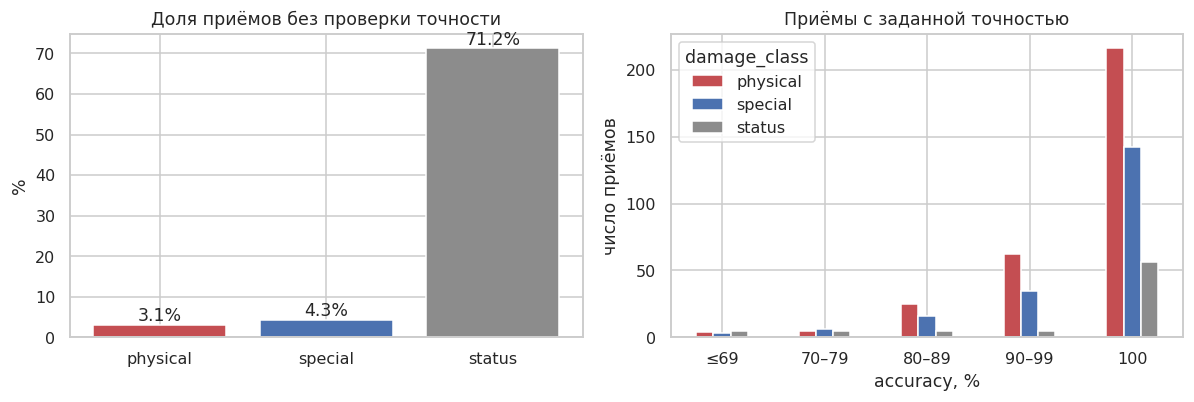

χ² (статусный ли приём × нет точности): χ² = 416.7, p = 1.27e-92
Доля приёмов со 100% точностью среди тех, у кого она задана: 70.2%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

no_acc = moves_u.groupby("damage_class", observed=True)["accuracy"].apply(lambda s: s.isna().mean() * 100)
bars = axes[0].bar(no_acc.index.astype(str), no_acc.values, color=["#C44E52", "#4C72B0", "#8C8C8C"])
axes[0].bar_label(bars, fmt="%.1f%%")
axes[0].set_title("Доля приёмов без проверки точности"); axes[0].set_ylabel("%")

acc_bins = pd.cut(moves_u["accuracy"], [0, 69, 79, 89, 99, 100],
                  labels=["≤69", "70–79", "80–89", "90–99", "100"])
acc_ct = pd.crosstab(acc_bins, moves_u["damage_class"])
acc_ct.plot(kind="bar", ax=axes[1], rot=0, color=["#C44E52", "#4C72B0", "#8C8C8C"])
axes[1].set_title("Приёмы с заданной точностью"); axes[1].set_xlabel("accuracy, %"); axes[1].set_ylabel("число приёмов")
plt.tight_layout(); plt.show()

ct = pd.crosstab(moves_u["damage_class"] == "status", moves_u["accuracy"].isna())
chi2, p, *_ = stats.chi2_contingency(ct)
print(f"χ² (статусный ли приём × нет точности): χ² = {chi2:.1f}, p = {p:.3g}")
print(f"Доля приёмов со 100% точностью среди тех, у кого она задана: {(moves_u['accuracy'] == 100).sum() / moves_u['accuracy'].notna().sum():.1%}")

**Вывод 5.** Гипотеза **подтверждается**. Не проверяют точность 71.2% статусных приёмов и только 3.1% физических и 4.3% специальных. Связь подтверждается критерием χ² (p ≈ 10⁻⁹²). Среди приёмов с заданной точностью 70.2% имеют 100%, а точность ниже 80% встречается редко. Правый график показывает, что неточные приёмы в основном атакующие: это компромисс «сильный, но может промахнуться».

## График 6. Связь PP и силы (`pp`, `power`)

**Гипотеза 6.** Чем сильнее приём, тем меньше у него PP (игровой баланс: мощный приём можно использовать реже).

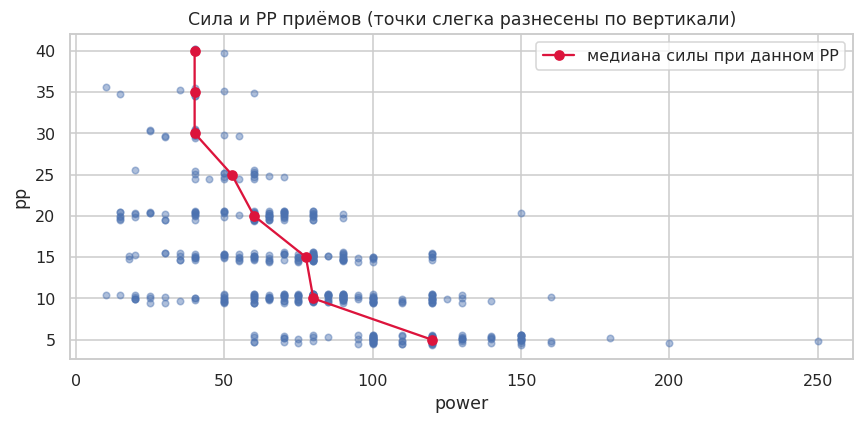

Корреляция Спирмена: ρ = -0.65, p = 7.17e-61
pp         5      10     15    20    25    30    35    40
count    95.0  171.0  102.0  78.0  18.0  16.0   9.0   4.0
median  120.0   80.0   77.5  60.0  52.5  40.0  40.0  40.0


In [16]:
rng = np.random.default_rng(0)
d6 = moves_u.dropna(subset=["power"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(d6["power"], d6["pp"] + rng.uniform(-0.6, 0.6, len(d6)), alpha=0.45, s=18, color="#4C72B0")
med = d6.groupby("pp")["power"].median()
ax.plot(med.values, med.index, "o-", color="crimson", label="медиана силы при данном PP")
ax.set_title("Сила и PP приёмов (точки слегка разнесены по вертикали)")
ax.set_xlabel("power"); ax.set_ylabel("pp"); ax.legend()
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(d6["pp"], d6["power"])
print(f"Корреляция Спирмена: ρ = {rho:.2f}, p = {p:.3g}")
print(d6.groupby("pp")["power"].agg(["count", "median"]).T)

**Вывод 6.** Гипотеза **подтверждается**. Связь отрицательная и сильная: коэффициент Спирмена ρ = −0.65 (p ≈ 10⁻⁶¹). Красная линия медиан монотонно убывает: при 5 PP медианная сила 120, при 10 PP — 80, при 20 PP — 60, при 30–40 PP — 40. Это и есть игровой баланс: мощный приём можно использовать реже.

## График 7. Приоритет (`priority`)

**Гипотеза 7.** Почти все приёмы имеют обычный приоритет 0, а приёмы с повышенным приоритетом (бьют первыми) слабее обычных: скорость компенсируется силой.

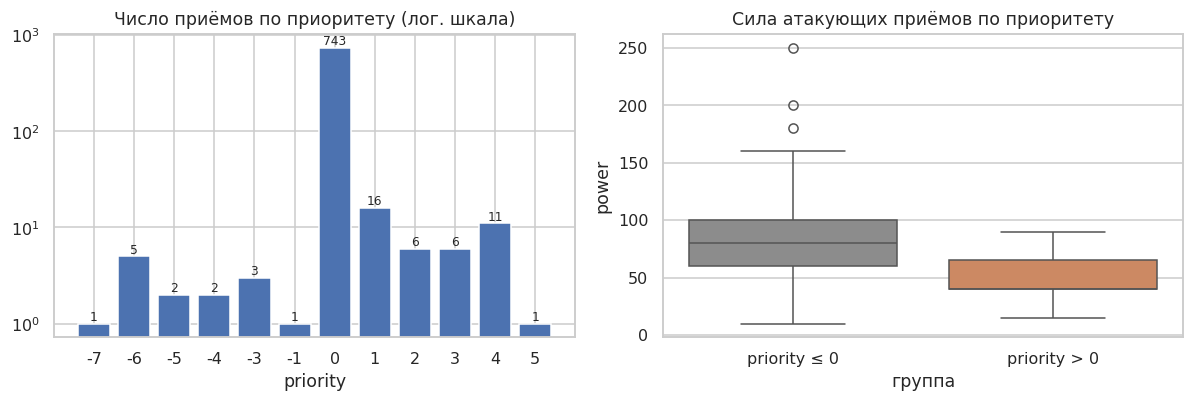

Доля приёмов с priority = 0: 93.2%
              count  mean   std   min   25%   50%    75%    max
группа                                                         
priority > 0   17.0  49.4  19.6  15.0  40.0  40.0   65.0   90.0
priority ≤ 0  476.0  79.2  33.4  10.0  60.0  80.0  100.0  250.0
Манн–Уитни (priority > 0 слабее): p = 4.91e-05


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
pr = moves_u["priority"].value_counts().sort_index()
bars = axes[0].bar(pr.index.astype(str), pr.values, color="#4C72B0")
axes[0].bar_label(bars, fontsize=8)
axes[0].set_yscale("log")
axes[0].set_title("Число приёмов по приоритету (лог. шкала)"); axes[0].set_xlabel("priority")

d7 = moves_u.dropna(subset=["power"]).copy()
d7["группа"] = np.where(d7["priority"] > 0, "priority > 0", "priority ≤ 0")
sns.boxplot(data=d7, x="группа", y="power", hue="группа", legend=False, order=["priority ≤ 0", "priority > 0"],
            palette=["#8C8C8C", "#DD8452"], ax=axes[1])
axes[1].set_title("Сила атакующих приёмов по приоритету")
plt.tight_layout(); plt.show()

print(f"Доля приёмов с priority = 0: {(moves_u['priority'] == 0).mean():.1%}")
print(d7.groupby("группа")["power"].describe().round(1))
res = stats.mannwhitneyu(d7.query("priority > 0")["power"], d7.query("priority <= 0")["power"], alternative="less")
print(f"Манн–Уитни (priority > 0 слабее): p = {res.pvalue:.3g}")

**Вывод 7.** Гипотеза **подтверждается**. Обычный приоритет 0 у 93.2% приёмов (на графике логарифмическая шкала, иначе остальные столбцы не видны). Атакующие приёмы с приоритетом > 0 заметно слабее: медиана силы 40 против 80, тест Манна–Уитни p ≈ 5·10⁻⁵. Ограничение: приоритетных атакующих приёмов всего 17, группа маленькая, но разница настолько большая, что тест всё равно значим. Отрицательный приоритет (приём срабатывает последним) встречается ещё реже — это особые приёмы с отложенным эффектом.

## График 8. Поколение приёма (`move_generation`)

**Гипотеза 8.** Старые приёмы (1–4 поколения) могут выучить гораздо больше покемонов, чем новые: у них было больше времени, чтобы попасть в наборы, а новые часто делают «фирменными» для одного покемона.

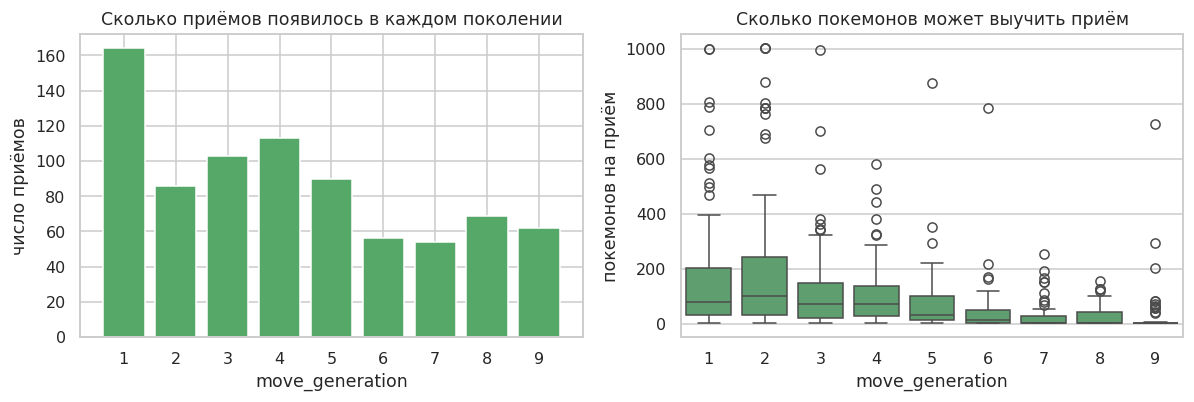

move_generation                1     2     3     4     5     6    7    8    9
медиана покемонов на приём  79.5  99.0  72.0  73.0  30.5  14.5  2.0  2.0  1.0
Спирмен (поколение приёма ~ число покемонов): ρ = -0.49, p = 1.02e-48
Приёмов, которые может выучить ровно 1 покемон: 134


In [18]:
learners = df.groupby("move", observed=True).size().rename("learners")
mg = moves_u.set_index("move").join(learners)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
cnt = mg["move_generation"].value_counts().sort_index()
axes[0].bar(cnt.index, cnt.values, color="#55A868")
axes[0].set_title("Сколько приёмов появилось в каждом поколении")
axes[0].set_xlabel("move_generation"); axes[0].set_ylabel("число приёмов"); axes[0].set_xticks(cnt.index)

sns.boxplot(data=mg, x="move_generation", y="learners", color="#55A868", ax=axes[1])
axes[1].set_title("Сколько покемонов может выучить приём")
axes[1].set_ylabel("покемонов на приём")
plt.tight_layout(); plt.show()

print(mg.groupby("move_generation")["learners"].median().rename("медиана покемонов на приём").to_frame().T)
rho, p = stats.spearmanr(mg["move_generation"], mg["learners"])
print(f"Спирмен (поколение приёма ~ число покемонов): ρ = {rho:.2f}, p = {p:.3g}")
print(f"Приёмов, которые может выучить ровно 1 покемон: {(mg['learners'] == 1).sum()}")

**Вывод 8.** Гипотеза **подтверждается**. Больше всего приёмов появилось в 1 поколении (164), начиная с 6 поколения — по 55–70. Медианное число покемонов, которые могут выучить приём: 72–99 у приёмов 1–4 поколений, 30 у 5-го, 15 у 6-го и всего 1–2 у приёмов 7–9 поколений. Корреляция Спирмена ρ = −0.49 (p ≈ 10⁻⁴⁸). 134 приёма может выучить только один покемон: это «фирменные» приёмы, и большинство их среди новых. Выбросы сверху у новых поколений — универсальные TM (например, Tera Blast из 9 поколения есть у ~730 покемонов).

## График 9. Поколение покемона (`pokemon_generation`) и размер набора приёмов

**Гипотеза 9.** У покемонов новых поколений набор приёмов меньше. Начиная с 8 поколения (Sword/Shield) разработчики сократили число TM и убрали часть приёмов из игр.

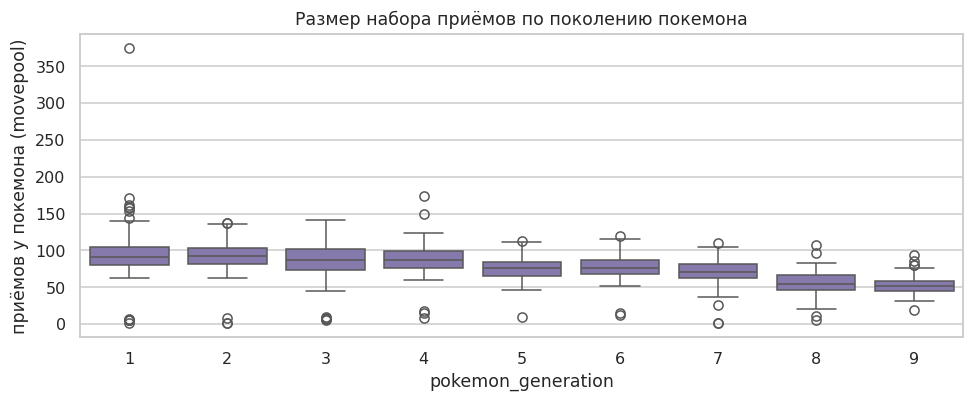

pokemon_generation     1     2     3     4     5     6     7     8     9
медиана             91.0  93.0  87.0  87.0  76.5  76.5  71.0  55.0  52.0
Краскел–Уоллис: H = 432.1, p = 2.58e-88
Спирмен: ρ = -0.61, p = 2.99e-107


In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=poke_u, x="pokemon_generation", y="movepool", color="#8172B3", ax=ax)
ax.set_title("Размер набора приёмов по поколению покемона")
ax.set_ylabel("приёмов у покемона (movepool)")
plt.tight_layout(); plt.show()

print(poke_u.groupby("pokemon_generation")["movepool"].median().rename("медиана").to_frame().T)
h, p = stats.kruskal(*[g["movepool"] for _, g in poke_u.groupby("pokemon_generation")])
rho, p2 = stats.spearmanr(poke_u["pokemon_generation"], poke_u["movepool"])
print(f"Краскел–Уоллис: H = {h:.1f}, p = {p:.3g}")
print(f"Спирмен: ρ = {rho:.2f}, p = {p2:.3g}")

**Вывод 9.** Гипотеза **подтверждается**, но с оговоркой. Медиана набора падает от 87–93 приёмов у покемонов 1–4 поколений до 71 в 7-м и 52–55 в 8–9 поколениях. Различия значимы по критерию Краскела–Уоллиса (p ≈ 10⁻⁸⁸), связь монотонная (Спирмен ρ = −0.61). Оговорка: пара «покемон — приём» попадает в датасет, если приём доступен **хотя бы в одной** игре. Старые покемоны были в большем числе игр и успели накопить приёмы, поэтому часть эффекта объясняется не политикой разработчиков, а временем. Чтобы разделить эти причины, нужно сравнить наборы внутри одной игры (например, только Scarlet/Violet).

## График 10. Тип покемона × тип приёма (`primary_type`, `move_type`)

Тепловая карта: какую долю от всех приёмов покемона данного основного типа составляют приёмы каждого типа (строки в сумме дают 100%).

**Гипотеза 10.** На диагонали значения выше, чем в остальной строке: покемоны чаще всего учат приёмы своего типа. Кроме того, приёмы типа `normal` есть у всех типов покемонов.

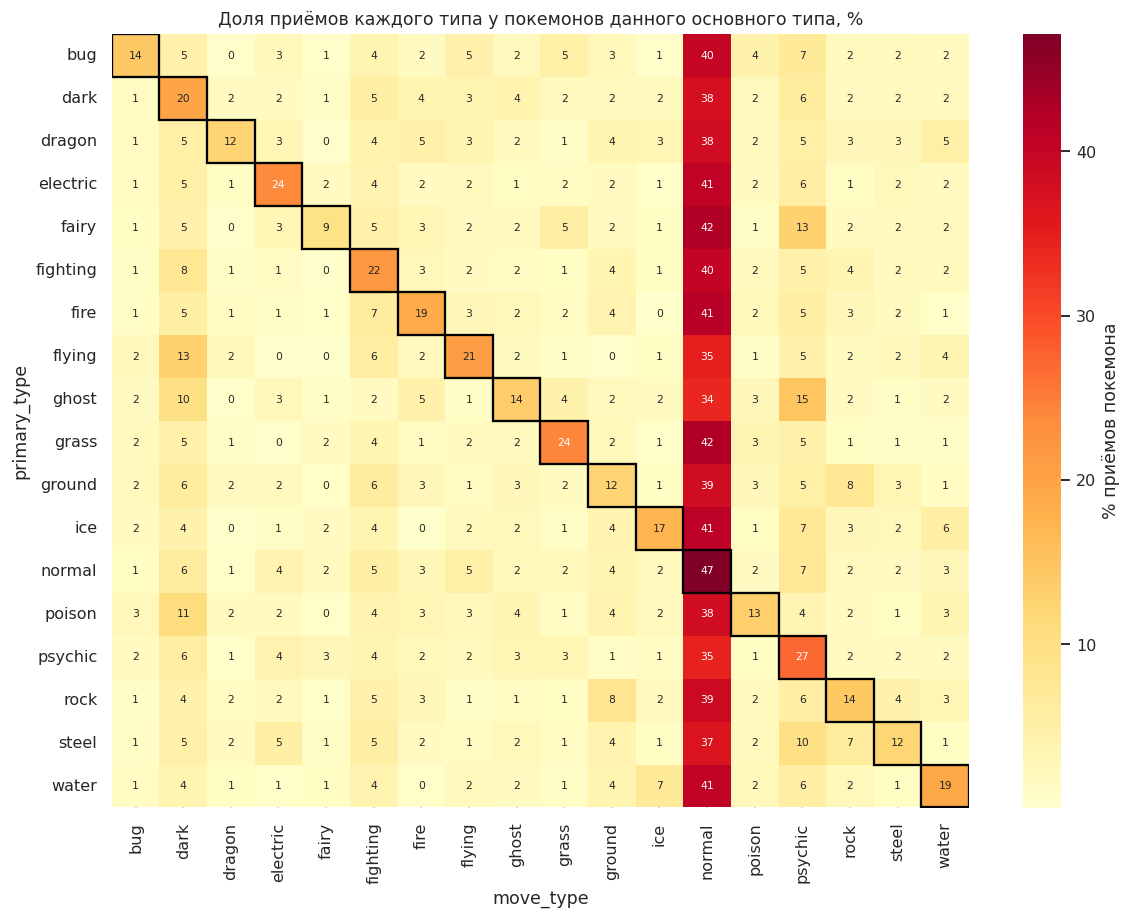

Normal — самый частый тип приёмов в строках: 18 из 18
Если не считать normal, свой тип — самый частый у 15 из 17 типов; исключения: ['fairy', 'ghost']
Средняя доля своего типа: 19.0% против 5.6% при равномерном распределении


In [20]:
heat = pd.crosstab(df["primary_type"], df["move_type"], normalize="index") * 100
order = sorted(heat.index)
heat = heat.loc[order, order]

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% приёмов покемона"}, ax=ax)
for i in range(len(order)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor="black", lw=1.5))
ax.set_title("Доля приёмов каждого типа у покемонов данного основного типа, %")
ax.set_xlabel("move_type"); ax.set_ylabel("primary_type")
plt.tight_layout(); plt.show()

diag = pd.Series(np.diag(heat), index=order)
top_in_row = heat.idxmax(axis=1)
non_normal = heat.drop(index="normal")
print("Normal — самый частый тип приёмов в строках:", (top_in_row == "normal").sum(), "из", len(order))
print("Если не считать normal, свой тип — самый частый у",
      (non_normal.drop(columns="normal").idxmax(axis=1) == non_normal.index).sum(), "из", len(non_normal), "типов;",
      "исключения:", list(non_normal.index[non_normal.drop(columns="normal").idxmax(axis=1) != non_normal.index]))
print(f"Средняя доля своего типа: {diag.mean():.1f}% против {100 / 18:.1f}% при равномерном распределении")

**Вывод 10.** Гипотеза **подтверждается**. Обе части видны на карте. Во-первых, приёмы типа `normal` — самые частые у покемонов **всех** 18 типов (столбец normal самый тёмный). Во-вторых, если не считать normal, свой тип — самый частый у 15 из 17 типов (диагональ в рамках выделяется). Средняя доля приёмов своего типа 19% при 5.6% для равномерного распределения. Исключения: у `fairy` и `ghost` приёмов своего типа меньше, чем `psychic`. Своих приёмов у этих типов мало (по 24 приёма), а тип fairy появился только в 6 поколении.

## График 11. STAB по способу изучения (`stab`, `learn_method`)

**Гипотеза 11.** Приёмы по уровню чаще совпадают с типом покемона (STAB), чем приёмы из TM: набор по уровню разработчики делают «под покемона», а TM общие для всех.

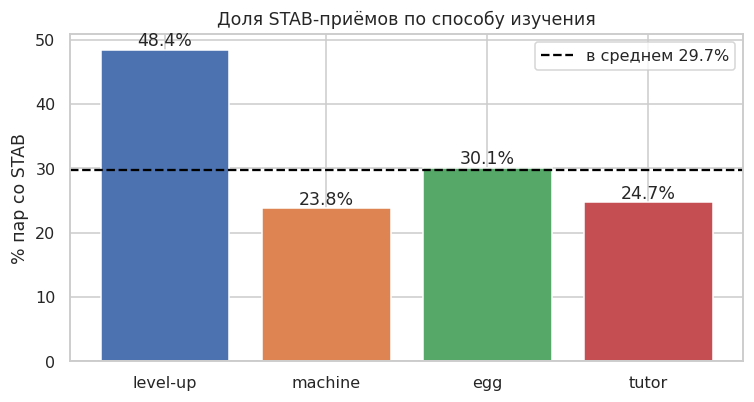

χ² = 4041.9, df = 3, p = 0


In [21]:
st = df.groupby("learn_method", observed=True)["stab"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(st.index.astype(str), st.values, color=sns.color_palette("deep", 4))
ax.bar_label(bars, fmt="%.1f%%")
ax.axhline(df["stab"].mean() * 100, color="black", ls="--", label=f"в среднем {df['stab'].mean():.1%}")
ax.set_title("Доля STAB-приёмов по способу изучения"); ax.set_ylabel("% пар со STAB"); ax.legend()
plt.tight_layout(); plt.show()

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["learn_method"], df["stab"]))
print(f"χ² = {chi2:.1f}, df = {dof}, p = {p:.3g}")

**Вывод 11.** Гипотеза **подтверждается**. STAB-приёмов среди изучаемых по уровню 48.4%, а среди TM — 23.8%, вдвое меньше. Через разведение 30.1%, у учителя 24.7%. Зависимость между способом изучения и STAB значима (χ² = 4042, p ≈ 0). Это согласуется с выводом 10: набор по уровню отражает «специализацию» покемона, а TM добавляют приёмы других типов для покрытия.

## График 12. Дополнительный тип (`secondary_type`)

**Гипотеза 12.** Примерно половина покемонов двухтипные, и самый частый дополнительный тип — `flying`. У двухтипных покемонов доля STAB-приёмов выше, потому что совпадение возможно с любым из двух типов.

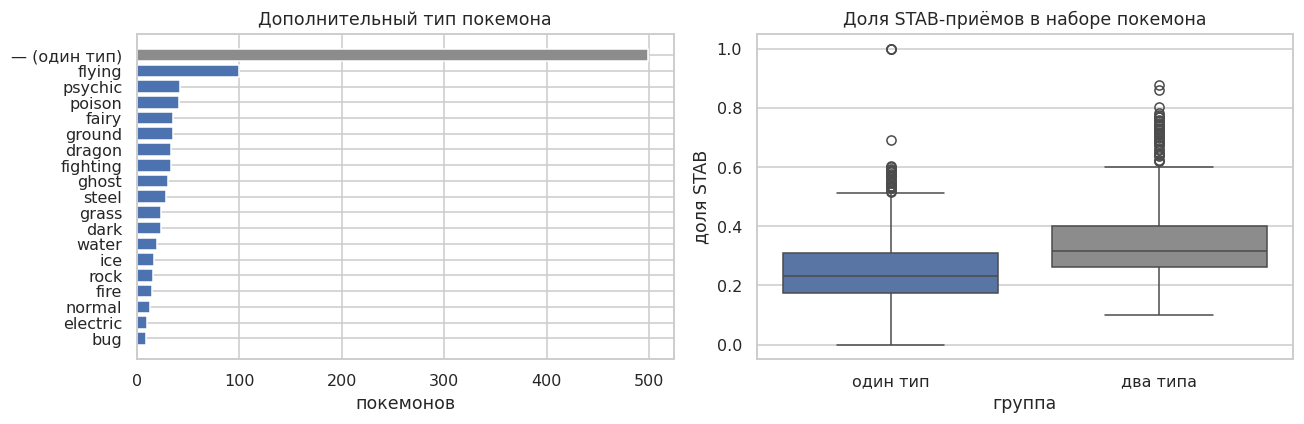

Доля двухтипных покемонов: 51.3%
группа
два типа    0.317
один тип    0.232
Name: stab, dtype: float64
Манн–Уитни (два типа > один): p = 1.16e-35


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sec = poke_u["secondary_type"].fillna("— (один тип)").value_counts()
colors = ["#8C8C8C" if i.startswith("—") else "#4C72B0" for i in sec.index]
axes[0].barh(sec.index[::-1], sec.values[::-1], color=colors[::-1])
axes[0].set_title("Дополнительный тип покемона"); axes[0].set_xlabel("покемонов")

per_poke = df.groupby("pokemon").agg(stab=("stab", "mean"), dual=("secondary_type", lambda s: s.notna().any()))
per_poke["группа"] = np.where(per_poke["dual"], "два типа", "один тип")
sns.boxplot(data=per_poke, x="группа", y="stab", hue="группа", legend=False, order=["один тип", "два типа"],
            palette=["#8C8C8C", "#4C72B0"], ax=axes[1])
axes[1].set_title("Доля STAB-приёмов в наборе покемона"); axes[1].set_ylabel("доля STAB")
plt.tight_layout(); plt.show()

print(f"Доля двухтипных покемонов: {poke_u['secondary_type'].notna().mean():.1%}")
print(per_poke.groupby("группа")["stab"].median().round(3))
res = stats.mannwhitneyu(per_poke.query("dual")["stab"], per_poke.query("not dual")["stab"], alternative="greater")
print(f"Манн–Уитни (два типа > один): p = {res.pvalue:.3g}")

**Вывод 12.** Гипотеза **подтверждается**. Двухтипных покемонов 51.3%, то есть примерно половина. Самый частый дополнительный тип — `flying` (100 покемонов, втрое больше, чем у следующего psychic). Медианная доля STAB-приёмов в наборе: 31.7% у двухтипных против 23.2% у однотипных, тест Манна–Уитни значим (p ≈ 10⁻³⁵). Заметим, что второй тип даёт прирост в 1.4 раза, а не в 2: приёмов дополнительного типа покемону дают меньше, чем основного.

## График 13. Атака и спец. атака (`attack`, `sp_attack`) и класс приёмов

Для каждого покемона считаем долю физических приёмов среди его атакующих приёмов.

**Гипотеза 13.** Набор приёмов подстроен под характеристики: чем больше `attack` превышает `sp_attack`, тем больше доля физических приёмов.

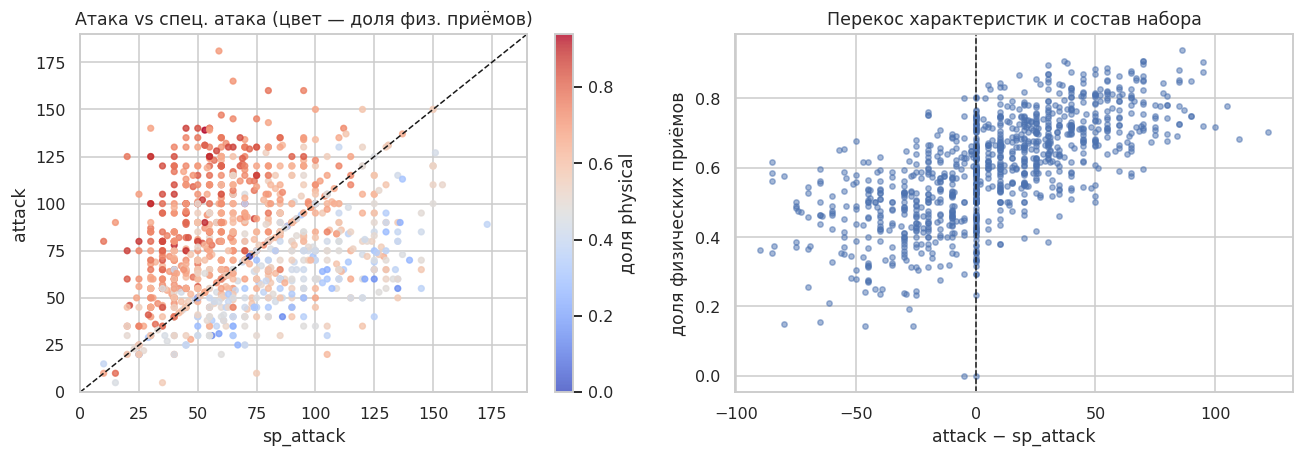

Спирмен: ρ = 0.72, p = 1.46e-161
diff
attack < sp_attack    0.487
attack > sp_attack    0.696
равны                 0.560
Name: медиана доли физ. приёмов, dtype: float64


In [23]:
atk = (df[df["damage_class"] != "status"]
       .assign(physical=lambda d: d["damage_class"] == "physical")
       .groupby("pokemon")["physical"].mean().rename("phys_share"))
d13 = poke_u.set_index("pokemon").join(atk).dropna(subset=["phys_share"])
d13["diff"] = d13["attack"] - d13["sp_attack"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sc = axes[0].scatter(d13["sp_attack"], d13["attack"], c=d13["phys_share"], cmap="coolwarm", s=14, alpha=0.8)
lim = [0, 190]; axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("sp_attack"); axes[0].set_ylabel("attack")
axes[0].set_title("Атака vs спец. атака (цвет — доля физ. приёмов)")
fig.colorbar(sc, ax=axes[0], label="доля physical")

axes[1].scatter(d13["diff"], d13["phys_share"], s=12, alpha=0.5, color="#4C72B0")
axes[1].axvline(0, color="k", lw=1, ls="--")
axes[1].set_xlabel("attack − sp_attack"); axes[1].set_ylabel("доля физических приёмов")
axes[1].set_title("Перекос характеристик и состав набора")
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(d13["diff"], d13["phys_share"])
print(f"Спирмен: ρ = {rho:.2f}, p = {p:.3g}")
print(d13.groupby(np.sign(d13["diff"]).map({-1: "attack < sp_attack", 0: "равны", 1: "attack > sp_attack"}))
         ["phys_share"].median().round(3).rename("медиана доли физ. приёмов"))

**Вывод 13.** Гипотеза **подтверждается**. На левом графике выше диагонали (attack > sp_attack) преобладают красные точки, ниже — синие. Связь разницы `attack − sp_attack` с долей физических приёмов сильная: Спирмен ρ = 0.72 (p ≈ 10⁻¹⁶¹). Медианная доля физических приёмов 69.6%, когда атака больше спец. атаки, и 48.7%, когда меньше. Любопытно, что даже «специальные» покемоны имеют почти половину физических приёмов: физических приёмов в игре в целом больше (график 3), и TM дают их всем.

## График 14. Сумма характеристик (`total_stats`) и размер набора приёмов

**Гипотеза 14.** Более сильные покемоны (с большей суммой характеристик) знают больше приёмов: это обычно финальные эволюции, которые наследуют приёмы предыдущих стадий и получают дополнительные.

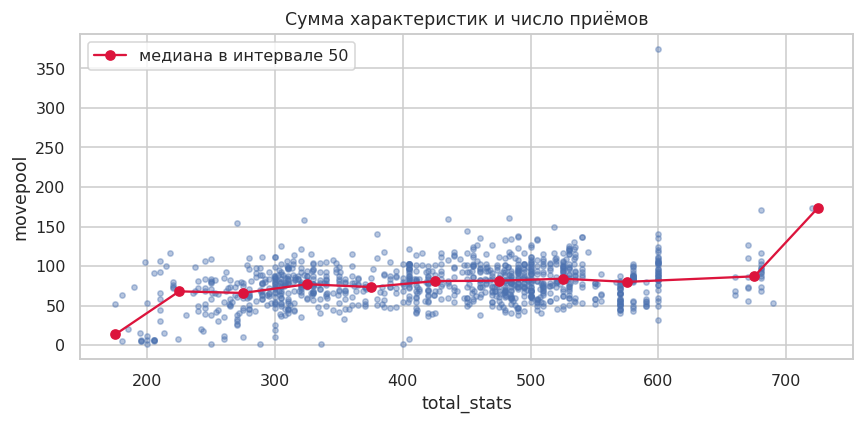

Спирмен: ρ = 0.24, p = 3.95e-15
stats_bin         ≤350  351–450  451–550  >550
медиана movepool  72.0     78.0     82.0  81.5


In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(poke_u["total_stats"], poke_u["movepool"], s=12, alpha=0.4, color="#4C72B0")
binned = poke_u.groupby(pd.cut(poke_u["total_stats"], range(150, 801, 50)), observed=True)["movepool"].median()
ax.plot([iv.mid for iv in binned.index], binned.values, "o-", color="crimson", label="медиана в интервале 50")
ax.legend()
ax.set_xlabel("total_stats"); ax.set_ylabel("movepool")
ax.set_title("Сумма характеристик и число приёмов")
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(poke_u["total_stats"], poke_u["movepool"])
print(f"Спирмен: ρ = {rho:.2f}, p = {p:.3g}")
poke_u["stats_bin"] = pd.cut(poke_u["total_stats"], [0, 350, 450, 550, 800], labels=["≤350", "351–450", "451–550", ">550"])
print(poke_u.groupby("stats_bin", observed=True)["movepool"].median().rename("медиана movepool").to_frame().T)

**Вывод 14.** Гипотеза **подтверждается слабо**. Глазом по облаку точек связь почти не видна, поэтому одного графика недостаточно. Тест Спирмена показывает положительную, но слабую связь: ρ = 0.24 (значима, p ≈ 10⁻¹⁵). По линии медиан видно, что рост есть только до ~450 (медиана набора 72 → 78 → 82), а дальше выходит на плато (81.5 у покемонов сильнее 550). Сумма характеристик объясняет размер набора плохо: важнее поколение (вывод 9) и конкретные исключения вроде Mew (375 приёмов).

## График 15. Категория покемона (`pokemon_category`) и сила приёмов

Для каждого покемона считаем среднюю силу его атакующих приёмов.

**Гипотеза 15.** Легендарные и мифические покемоны учат более сильные приёмы, чем обычные.

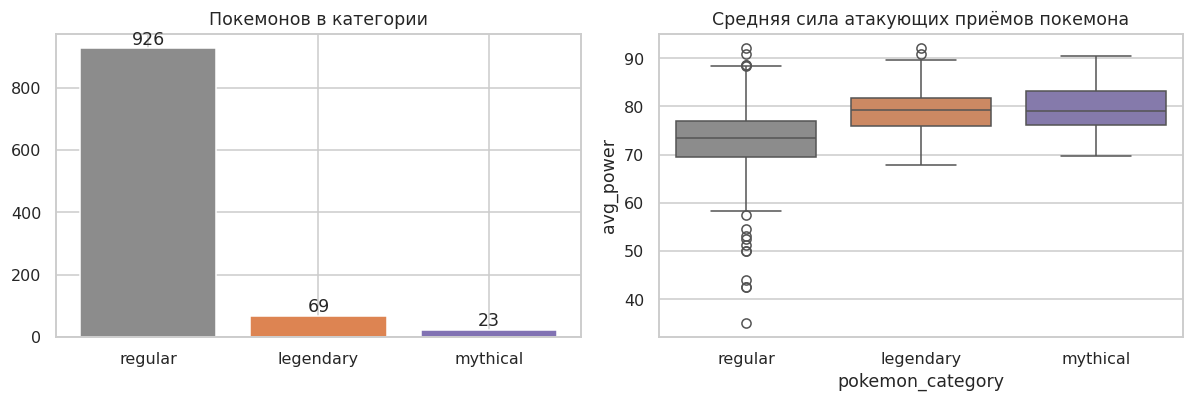

pokemon_category
regular      73.5
legendary    79.2
mythical     79.0
Name: медиана, dtype: float64
Манн–Уитни (легендарные+мифические > обычные): p = 8.81e-22


In [25]:
avg_pow = df.dropna(subset=["power"]).groupby("pokemon")["power"].mean().rename("avg_power")
d15 = poke_u.set_index("pokemon").join(avg_pow).dropna(subset=["avg_power"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
cnt = d15["pokemon_category"].value_counts().reindex(["regular", "legendary", "mythical"])
bars = axes[0].bar(cnt.index, cnt.values, color=["#8C8C8C", "#DD8452", "#8172B3"])
axes[0].bar_label(bars); axes[0].set_title("Покемонов в категории")
sns.boxplot(data=d15, x="pokemon_category", y="avg_power", hue="pokemon_category", legend=False,
            palette=["#8C8C8C", "#DD8452", "#8172B3"], ax=axes[1])
axes[1].set_title("Средняя сила атакующих приёмов покемона")
plt.tight_layout(); plt.show()

print(d15.groupby("pokemon_category", observed=True)["avg_power"].median().round(1).rename("медиана"))
special = d15["pokemon_category"] != "regular"
res = stats.mannwhitneyu(d15.loc[special, "avg_power"], d15.loc[~special, "avg_power"], alternative="greater")
print(f"Манн–Уитни (легендарные+мифические > обычные): p = {res.pvalue:.3g}")

**Вывод 15.** На первый взгляд гипотеза **подтверждается**: медианная средняя сила приёмов 79.2 у легендарных, 79.0 у мифических и 73.5 у обычных, тест Манна–Уитни значим (p ≈ 10⁻²¹). Но легендарные покемоны в целом сильнее обычных, поэтому разница может объясняться не категорией, а силой покемона. Одного графика недостаточно, нужна дополнительная проверка.

**Дополнительная проверка 15.** Возможно, дело не в категории, а в том, что легендарные просто сильнее: у сильных покемонов и приёмы сильнее. Проверим, сохраняется ли разница среди покемонов с одинаково высокой суммой характеристик (≥ 580).

In [26]:
strong = d15[d15["total_stats"] >= 580]
print(strong.groupby("pokemon_category", observed=True)["avg_power"].agg(["count", "median"]).round(1))
sp = strong["pokemon_category"] != "regular"
res = stats.mannwhitneyu(strong.loc[sp, "avg_power"], strong.loc[~sp, "avg_power"], alternative="greater")
print(f"Манн–Уитни среди сильных (total_stats ≥ 580): p = {res.pvalue:.3g}")
rho, p = stats.spearmanr(d15["total_stats"], d15["avg_power"])
print(f"Спирмен total_stats ~ avg_power по всем покемонам: ρ = {rho:.2f}, p = {p:.3g}")

                  count  median
pokemon_category               
regular              20    79.9
legendary            51    79.4
mythical             21    79.0
Манн–Уитни среди сильных (total_stats ≥ 580): p = 0.702
Спирмен total_stats ~ avg_power по всем покемонам: ρ = 0.62, p = 2.22e-107


**Вывод (доп.).** После проверки гипотеза **опровергается**: дело не в категории. Среди покемонов с одинаково высокой суммой характеристик (≥ 580) обычные учат приёмы той же силы, что легендарные и мифические (медианы 79.9, 79.4 и 79.0, p = 0.70). При этом по всем покемонам сила приёмов заметно растёт с суммой характеристик (Спирмен ρ = 0.62). Значит, «легендарность» — мешающий фактор: она связана с силой покемона, а сила связана с силой приёмов.

## График 16. Самые распространённые приёмы и самые большие наборы (`move`, `pokemon`)

**Гипотеза 16.** Самые распространённые приёмы — универсальные статусные приёмы из TM, а не атакующие. Размер набора приёмов у покемонов сильно различается: есть покемоны-исключения с наборами из 1–2 приёмов.

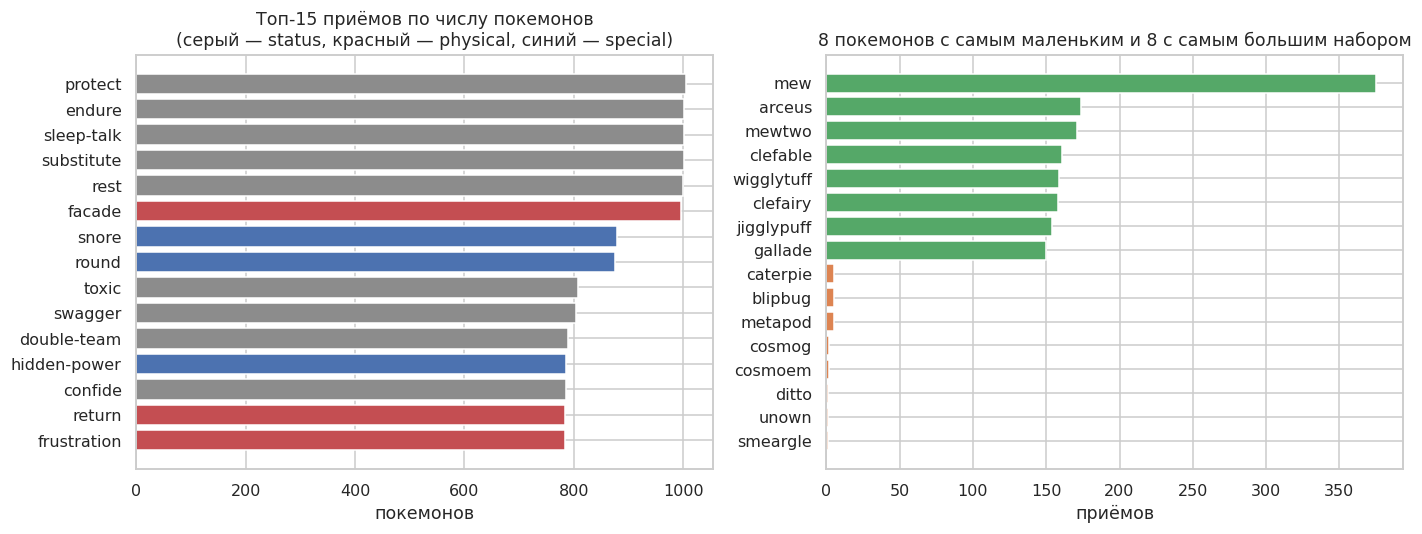

Распределение movepool: медиана 78, IQR 62–93
Классы урона в топ-15: {'status': 9, 'physical': 3, 'special': 3}
Способ изучения топ-5 приёмов: {'machine': 0.953, 'level-up': 0.038, 'tutor': 0.009, 'egg': 0.0}


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_moves = df.groupby(["move", "damage_class"], observed=True).size().sort_values(ascending=False).head(15)
cols = top_moves.index.get_level_values(1).map({"physical": "#C44E52", "special": "#4C72B0", "status": "#8C8C8C"})
axes[0].barh([m for m, _ in top_moves.index][::-1], top_moves.values[::-1], color=list(cols)[::-1])
axes[0].set_title("Топ-15 приёмов по числу покемонов\n(серый — status, красный — physical, синий — special)")
axes[0].set_xlabel("покемонов")

ext = pd.concat([poke_u.nlargest(8, "movepool"), poke_u.nsmallest(8, "movepool")]).sort_values("movepool")
axes[1].barh(ext["pokemon"], ext["movepool"], color=["#DD8452"] * 8 + ["#55A868"] * 8)
axes[1].set_title("8 покемонов с самым маленьким и 8 с самым большим набором")
axes[1].set_xlabel("приёмов")
plt.tight_layout(); plt.show()

print(f"Распределение movepool: медиана {poke_u['movepool'].median():.0f}, IQR {poke_u['movepool'].quantile(0.25):.0f}–{poke_u['movepool'].quantile(0.75):.0f}")
print("Классы урона в топ-15:", top_moves.index.get_level_values(1).value_counts().to_dict())
print("Способ изучения топ-5 приёмов:", df[df["move"].isin([m for m, _ in top_moves.index[:5]])]["learn_method"].value_counts(normalize=True).round(3).to_dict())

**Вывод 16.** Гипотеза **подтверждается**. Топ-5 приёмов — статусные Protect, Sleep Talk, Endure, Substitute и Rest: их может выучить ~1000 из 1025 покемонов, и в 95% случаев через TM. В топ-15 статусных 9 из 15, первый атакующий приём — Facade. Размер набора сильно различается: медиана 78 приёмов, межквартильный размах 62–93, но Mew знает 375 приёмов (может выучить почти любой TM), а у Smeargle, Ditto и Unown по одному приёму. Это не ошибка данных: у них один «особый» приём (Sketch копирует любой приём, Transform копирует противника, у Unown только Hidden Power).

## Итоги

**Часть 1.** Данные взяты из того же источника, что в ЛР1 (PokeAPI). Число покемонов ограничено (1025), поэтому объектом стала пара «покемон — приём, который он может выучить». Получилось ≈79.6 тыс. объектов и 19 признаков: номинальные, порядковые, интервальный (`priority`) и количественные признаки шкалы отношений. Данные реальные, собраны через REST API и сохранены в SQLite.

**Часть 2.** Построено 16 графиков (плюс дополнительная проверка к графику 15), охвачены все 19 признаков:

| График | Признаки | Гипотеза |
|---|---|---|
| 1 | learn_method | подтверждена |
| 2 | level_learned | подтверждена |
| 3 | damage_class | подтверждена частично |
| 4 | power, damage_class | подтверждена |
| 5 | accuracy, damage_class | подтверждена |
| 6 | pp, power | подтверждена |
| 7 | priority, power | подтверждена |
| 8 | move_generation | подтверждена |
| 9 | pokemon_generation | подтверждена (с оговоркой) |
| 10 | primary_type, move_type | подтверждена |
| 11 | stab, learn_method | подтверждена |
| 12 | secondary_type, stab | подтверждена |
| 13 | attack, sp_attack, damage_class | подтверждена |
| 14 | total_stats | подтверждена слабо |
| 15 | pokemon_category, power, total_stats | опровергнута после доп. проверки |
| 16 | move, pokemon | подтверждена |

**Главные наблюдения:**
* наборы приёмов в основном состоят из TM (2/3 пар), а «специализация» покемона видна в приёмах по уровню: почти половина из них STAB;
* у приёмов есть явный баланс: сила обратно связана с PP и приоритетом, неточные приёмы в основном атакующие;
* набор приёмов подстроен под характеристики (физические приёмы — атакующим покемонам) и под типы (свой тип — самый частый после normal);
* покемоны новых поколений знают заметно меньше приёмов, а новые приёмы чаще «фирменные»;
* легендарные покемоны учат более сильные приёмы только потому, что они сами сильнее: при равной сумме характеристик разницы нет.